In [1]:
!pip -q install requests owslib rasterio geopandas shapely pyproj matplotlib pandas

import os
import json
import zipfile
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from owslib.wcs import WebCoverageService
from pyproj import Transformer
from shapely.geometry import box, mapping
from shapely.ops import transform as transform_geometry
from rasterio.features import geometry_mask
from IPython.display import display

# Output folder
OUTPUT_DIR = "/content/soilgrids_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# El Zankalon AOI
west, south = 31.35, 30.44
east, north = 31.55, 30.64

aoi = box(west, south, east, north)

# SoilGrids projection
soilgrids_crs = "+proj=igh +datum=WGS84 +no_defs +towgs84=0,0,0"

transformer = Transformer.from_crs(
    "EPSG:4326",
    soilgrids_crs,
    always_xy=True
)

projected_aoi = transform_geometry(
    transformer.transform,
    aoi
)

xmin, ymin, xmax, ymax = projected_aoi.bounds

projected_bbox = (xmin, ymin, xmax, ymax)

print("Setup completed!")
print("AOI:", aoi.bounds)
print("Projected BBOX:", projected_bbox)
print("Output folder:", OUTPUT_DIR)

Setup completed!
AOI: (31.35, 30.44, 31.55, 30.64)
Projected BBOX: (3468884.727218316, 3388565.2997472477, 3488346.333882893, 3410829.1979059023)
Output folder: /content/soilgrids_output


/tmp/ipykernel_1429/2981944573.py:37: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  projected_aoi = transform_geometry(


In [2]:
properties = {
    "ph": {
        "service": "phh2o",
        "url": "https://maps.isric.org/mapserv?map=/map/phh2o.map"
    },
    "soc": {
        "service": "soc",
        "url": "https://maps.isric.org/mapserv?map=/map/soc.map"
    },
    "clay": {
        "service": "clay",
        "url": "https://maps.isric.org/mapserv?map=/map/clay.map"
    },
    "sand": {
        "service": "sand",
        "url": "https://maps.isric.org/mapserv?map=/map/sand.map"
    },
    "silt": {
        "service": "silt",
        "url": "https://maps.isric.org/mapserv?map=/map/silt.map"
    },
    "cec": {
        "service": "cec",
        "url": "https://maps.isric.org/mapserv?map=/map/cec.map"
    },
    "nitrogen": {
        "service": "nitrogen",
        "url": "https://maps.isric.org/mapserv?map=/map/nitrogen.map"
    },
    "bdod": {
        "service": "bdod",
        "url": "https://maps.isric.org/mapserv?map=/map/bdod.map"
    }
}

downloaded_files = {}

for name, info in properties.items():

    print(f"\nDownloading {name.upper()}...")

    wcs = WebCoverageService(
        info["url"],
        version="1.0.0"
    )

    coverage_id = f"{info['service']}_0-5cm_Q0.5"

    if coverage_id not in wcs.contents:
        raise ValueError(f"Coverage not available: {coverage_id}")

    response = wcs.getCoverage(
        identifier=coverage_id,
        bbox=projected_bbox,
        crs="urn:ogc:def:crs:EPSG::152160",
        resx=250,
        resy=250,
        format="GEOTIFF_INT16",
        timeout=180
    )

    file_bytes = response.read()

    if file_bytes[:4] not in [b"II*\x00", b"MM\x00*"]:
        raise RuntimeError(
            f"Download failed for {name}:\n"
            + file_bytes[:1000].decode("utf-8", errors="replace")
        )

    filename = os.path.join(
        OUTPUT_DIR,
        f"soilgrids_{name}.tif"
    )

    with open(filename, "wb") as f:
        f.write(file_bytes)

    downloaded_files[name] = filename

    print("Downloaded successfully!")
    print("File size:", len(file_bytes), "bytes")

print("\nAll 8 SoilGrids properties downloaded!")


Downloaded successfully!
File size: 4241 bytes

Downloaded successfully!
File size: 9178 bytes

Downloaded successfully!
File size: 8338 bytes

Downloaded successfully!
File size: 8218 bytes

Downloaded successfully!
File size: 8570 bytes

Downloaded successfully!
File size: 6309 bytes

Downloaded successfully!
File size: 9002 bytes

Downloaded successfully!
File size: 5825 bytes

All 8 SoilGrids properties downloaded!



Processing PH...


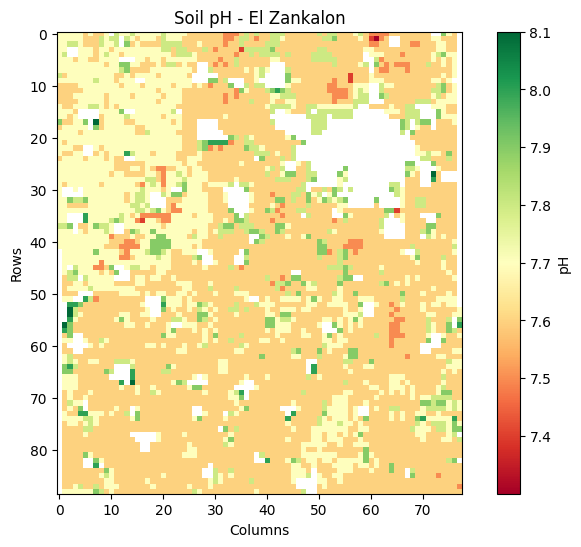

Clean file saved: /content/soilgrids_output/soilgrids_ph_clean.tif
Mean: 7.64902
Min: 7.3
Max: 8.1

Processing SOC...


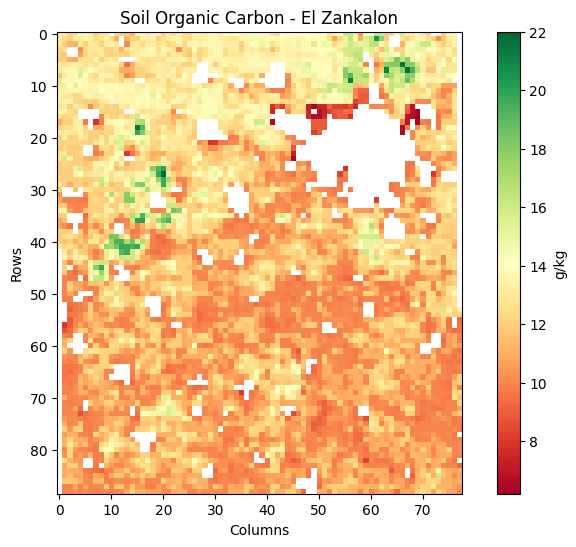

Clean file saved: /content/soilgrids_output/soilgrids_soc_clean.tif
Mean: 11.668472
Min: 6.2
Max: 22.0

Processing CLAY...


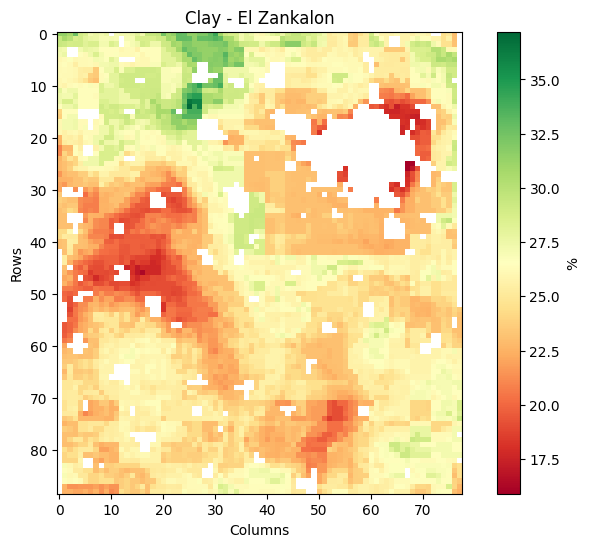

Clean file saved: /content/soilgrids_output/soilgrids_clay_clean.tif
Mean: 24.757374
Min: 15.9
Max: 37.2

Processing SAND...


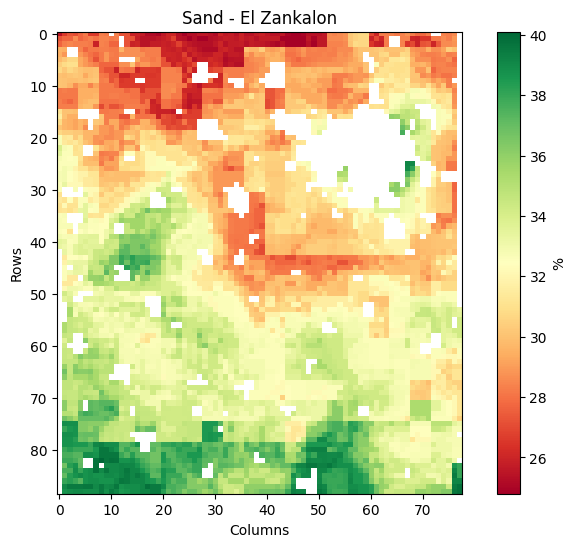

Clean file saved: /content/soilgrids_output/soilgrids_sand_clean.tif
Mean: 32.17701
Min: 24.8
Max: 40.1

Processing SILT...


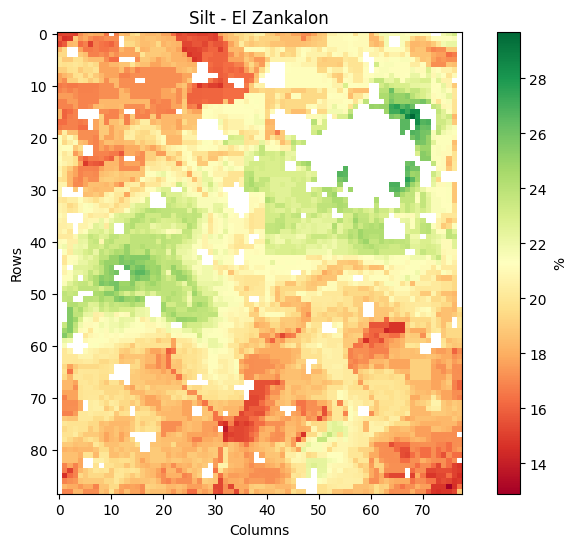

Clean file saved: /content/soilgrids_output/soilgrids_silt_clean.tif
Mean: 19.973776
Min: 12.9
Max: 29.7

Processing CEC...


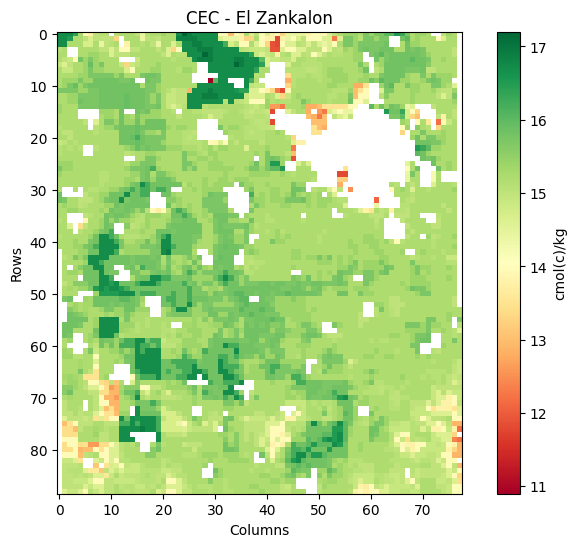

Clean file saved: /content/soilgrids_output/soilgrids_cec_clean.tif
Mean: 15.299869
Min: 10.9
Max: 17.2

Processing NITROGEN...


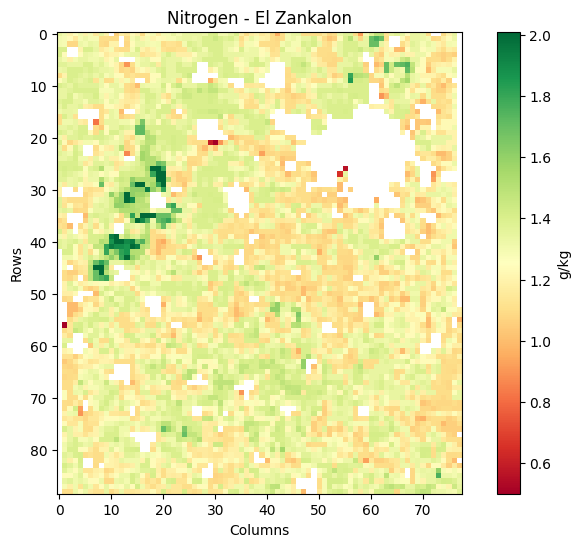

Clean file saved: /content/soilgrids_output/soilgrids_nitrogen_clean.tif
Mean: 1.26516
Min: 0.5
Max: 2.01

Processing BDOD...


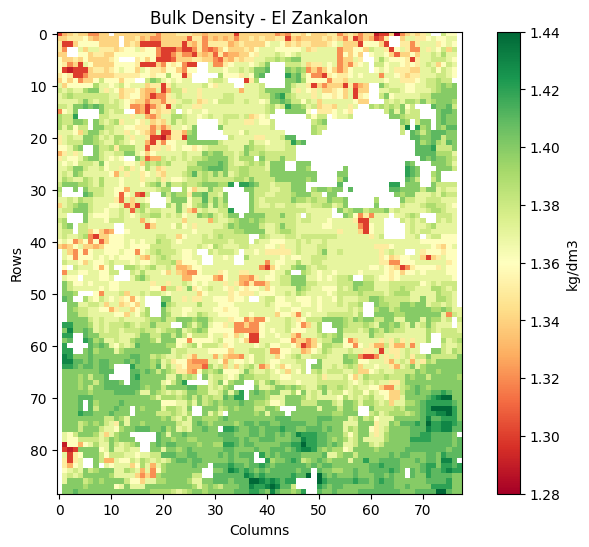

Clean file saved: /content/soilgrids_output/soilgrids_bdod_clean.tif
Mean: 1.3767543
Min: 1.28
Max: 1.44

FINAL SUMMARY


,Property,Unit,Mean,Min,Max,Std,Valid_Pixels,Missing_Pixels
0,PH,pH,7.649020,7.300000,8.100000,0.084903,6128,814
1,SOC,g/kg,11.668472,6.200000,22.000000,1.733375,6128,814
2,CLAY,%,24.757374,15.900000,37.200001,2.693006,6128,814
3,SAND,%,32.177010,24.799999,40.099998,3.132427,6128,814
4,SILT,%,19.973776,12.900000,29.700001,2.365739,6128,814
5,CEC,cmol(c)/kg,15.299869,10.900000,17.200001,0.622267,6128,814
6,NITROGEN,g/kg,1.265160,0.500000,2.010000,0.146140,6128,814
7,BDOD,kg/dm3,1.376754,1.280000,1.440000,0.024207,6128,814



All clean rasters and maps saved!


In [3]:
conversion = {
    "ph": {"factor": 10, "unit": "pH", "label": "Soil pH"},
    "soc": {"factor": 10, "unit": "g/kg", "label": "Soil Organic Carbon"},
    "clay": {"factor": 10, "unit": "%", "label": "Clay"},
    "sand": {"factor": 10, "unit": "%", "label": "Sand"},
    "silt": {"factor": 10, "unit": "%", "label": "Silt"},
    "cec": {"factor": 10, "unit": "cmol(c)/kg", "label": "CEC"},
    "nitrogen": {"factor": 100, "unit": "g/kg", "label": "Nitrogen"},
    "bdod": {"factor": 100, "unit": "kg/dm3", "label": "Bulk Density"}
}

cleaned_data = {}
summary = []
reference = None

for name, info in conversion.items():

    print(f"\nProcessing {name.upper()}...")

    original_file = downloaded_files[name]

    with rasterio.open(original_file) as src:

        raw = src.read(1).astype("float32")
        profile = src.profile.copy()
        nodata = src.nodata

        if reference is None:
            reference = {
                "shape": src.shape,
                "crs": src.crs,
                "transform": src.transform,
                "bounds": src.bounds
            }
        else:
            if src.shape != reference["shape"]:
                raise ValueError(f"{name}: Shape mismatch!")

            if src.crs != reference["crs"]:
                raise ValueError(f"{name}: CRS mismatch!")

            if not np.allclose(
                tuple(src.transform),
                tuple(reference["transform"]),
                rtol=0,
                atol=1e-6
            ):
                raise ValueError(f"{name}: Pixel alignment mismatch!")

        raster_transform = src.transform

    # Handle NoData
    if nodata is not None:
        raw[raw == nodata] = np.nan

    # Mask pixels outside the exact AOI
    inside_aoi = geometry_mask(
        [mapping(projected_aoi)],
        out_shape=raw.shape,
        transform=raster_transform,
        invert=True
    )

    raw[~inside_aoi] = np.nan

    # Convert to physical units
    clean = raw / info["factor"]

    valid = clean[np.isfinite(clean)]

    if valid.size == 0:
        raise ValueError(f"{name}: No valid pixels!")

    # Save clean raster
    profile.update(
        driver="GTiff",
        dtype="float32",
        nodata=-9999,
        compress="lzw"
    )

    clean_file = os.path.join(
        OUTPUT_DIR,
        f"soilgrids_{name}_clean.tif"
    )

    output_array = np.where(
        np.isfinite(clean),
        clean,
        -9999
    ).astype("float32")

    with rasterio.open(clean_file, "w", **profile) as dst:
        dst.write(output_array, 1)

    cleaned_data[name] = clean

    # Statistics
    summary.append({
        "Property": name.upper(),
        "Unit": info["unit"],
        "Mean": float(np.mean(valid)),
        "Min": float(np.min(valid)),
        "Max": float(np.max(valid)),
        "Std": float(np.std(valid)),
        "Valid_Pixels": int(valid.size),
        "Missing_Pixels": int(clean.size - valid.size)
    })

    # Save map
    plt.figure(figsize=(9, 6))

    plt.imshow(clean, cmap="RdYlGn")
    plt.colorbar(label=info["unit"])
    plt.title(f"{info['label']} - El Zankalon")
    plt.xlabel("Columns")
    plt.ylabel("Rows")

    map_file = os.path.join(
        OUTPUT_DIR,
        f"soilgrids_{name}_map.png"
    )

    plt.savefig(map_file, dpi=200, bbox_inches="tight")
    plt.show()

    print("Clean file saved:", clean_file)
    print("Mean:", np.mean(valid))
    print("Min:", np.min(valid))
    print("Max:", np.max(valid))

# Create summary table
summary_df = pd.DataFrame(summary)

summary_file = os.path.join(
    OUTPUT_DIR,
    "soilgrids_summary.csv"
)

summary_df.to_csv(summary_file, index=False)

print("\nFINAL SUMMARY")
display(summary_df)

print("\nAll clean rasters and maps saved!")

In [6]:
print("========== QUALITY CHECK ==========")

# Check all raster dimensions and alignment
for name in conversion:

    filename = os.path.join(
        OUTPUT_DIR,
        f"soilgrids_{name}_clean.tif"
    )

    with rasterio.open(filename) as src:

        assert src.shape == reference["shape"]
        assert src.crs == reference["crs"]
        assert np.allclose(
            tuple(src.transform),
            tuple(reference["transform"]),
            rtol=0,
            atol=1e-6
        )

        print(
            name.upper(),
            "| Shape:", src.shape,
            "| Valid:", src.read(1, masked=True).count()
        )

# Check soil texture fractions
texture_sum = (
    cleaned_data["clay"]
    + cleaned_data["sand"]
    + cleaned_data["silt"]
)

valid_texture = texture_sum[np.isfinite(texture_sum)]

print("\n========== SOIL TEXTURE CHECK ==========")

print("Mean texture sum:", np.mean(valid_texture))
print("Minimum sum:", np.min(valid_texture))
print("Maximum sum:", np.max(valid_texture))

print(
    "Pixels with texture sum between 95 and 105:",
    np.sum((valid_texture >= 95) & (valid_texture <= 105)),
    "out of",
    len(valid_texture)
)

# Save texture check
texture_df = pd.DataFrame({
    "Mean_Texture_Sum": [np.mean(valid_texture)],
    "Min_Texture_Sum": [np.min(valid_texture)],
    "Max_Texture_Sum": [np.max(valid_texture)],
    "Valid_Texture_Pixels": [len(valid_texture)]
})

texture_df.to_csv(
    os.path.join(OUTPUT_DIR, "soilgrids_texture_check.csv"),
    index=False
)

# Save metadata
metadata = {
    "Source": "ISRIC SoilGrids 2.0",
    "Study_Area": "El Zankalon, Sharqia, Egypt",
    "Depth": "0-5 cm",
    "Quantile": "Q0.5 Median",
    "Resolution_Target": "250 m",
    "AOI_WGS84": {
        "west": west,
        "south": south,
        "east": east,
        "north": north
    },
    "Properties": list(properties.keys()),
    "Note": "SoilGrids represents static soil property predictions, not daily observations."
}

with open(
    os.path.join(OUTPUT_DIR, "soilgrids_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

# Create ZIP
zip_path = "/content/SoilGrids_El_Zankalon.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, files in os.walk(OUTPUT_DIR):

        for filename in files:

            filepath = os.path.join(root, filename)

            arcname = os.path.relpath(filepath, OUTPUT_DIR)

            zipf.write(filepath, arcname)

print("\n FINAL RESULT")
print("All quality checks passed.")
print("ZIP created:", zip_path)

from google.colab import files
files.download(zip_path)

========== QUALITY CHECK ==========
PH | Shape: (89, 78) | Valid: 6128
SOC | Shape: (89, 78) | Valid: 6128
CLAY | Shape: (89, 78) | Valid: 6128
SAND | Shape: (89, 78) | Valid: 6128
SILT | Shape: (89, 78) | Valid: 6128
CEC | Shape: (89, 78) | Valid: 6128
NITROGEN | Shape: (89, 78) | Valid: 6128
BDOD | Shape: (89, 78) | Valid: 6128

========== SOIL TEXTURE CHECK ==========
Mean texture sum: 76.908165
Minimum sum: 70.1
Maximum sum: 84.09999
Pixels with texture sum between 95 and 105: 0 out of 6128

========== FINAL RESULT ==========
All quality checks passed.
ZIP created: /content/SoilGrids_El_Zankalon.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
texture_properties = ["clay", "sand", "silt"]

mean_texture = {}

for name in texture_properties:

    url = f"https://maps.isric.org/mapserv?map=/{'map'}/{name}.map"

    wcs = WebCoverageService(url, version="1.0.0")

    response = wcs.getCoverage(
        identifier=f"{name}_0-5cm_mean",
        bbox=projected_bbox,
        crs="urn:ogc:def:crs:EPSG::152160",
        resx=250,
        resy=250,
        format="GEOTIFF_INT16",
        timeout=180
    )

    file_bytes = response.read()

    if file_bytes[:4] not in [b"II*\x00", b"MM\x00*"]:
        raise RuntimeError(f"{name} mean download failed")

    filename = f"/content/soilgrids_output/soilgrids_{name}_mean.tif"

    with open(filename, "wb") as f:
        f.write(file_bytes)

    with rasterio.open(filename) as src:
        values = src.read(1).astype("float32")
        nodata = src.nodata

    if nodata is not None:
        values[values == nodata] = np.nan

    mean_texture[name] = values / 10

    print(name.upper(), "Mean layer downloaded!")

texture_sum_mean = (
    mean_texture["clay"]
    + mean_texture["sand"]
    + mean_texture["silt"]
)

valid = np.isfinite(texture_sum_mean)

print("\nMean texture sum:")
print("Average:", np.nanmean(texture_sum_mean))
print("Minimum:", np.nanmin(texture_sum_mean))
print("Maximum:", np.nanmax(texture_sum_mean))
print(
    "Pixels between 95 and 105:",
    np.sum((texture_sum_mean[valid] >= 95) &
           (texture_sum_mean[valid] <= 105)),
    "out of",
    np.sum(valid)
)

CLAY Mean layer downloaded!
SAND Mean layer downloaded!
SILT Mean layer downloaded!

Mean texture sum:
Average: 100.00091
Minimum: 99.899994
Maximum: 100.100006
Pixels between 95 and 105: 6219 out of 6219
